## 1️⃣ Setup & configuration

In [ ]:
import os, json, random, hashlib, zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: True


In [ ]:
# ---------------- Configuration (edit here only) ----------------
ZIP_PATH     = "/content/cnn_image.zip"   # path to your uploaded dataset zip
IMG_SIZE     = (224, 224)                 # MobileNetV2 native resolution
BATCH_SIZE   = 32
EPOCHS_HEAD  = 10                         # stage 1: train only the new classifier head
EPOCHS_FINE  = 15                         # stage 2: fine-tune the top of the backbone
FINE_TUNE_LAYERS = 40                     # how many backbone layers to unfreeze
MODEL_PATH   = "cat_dog_horse_model.keras"

## 2️⃣ Dataset

Expected structure (one folder per class inside each split):

```
cnn_image_quiz_3000/
├── train/        cat/  dog/  horse/
├── validation/   cat/  dog/  horse/
└── test/         cat/  dog/  horse/
```

In [ ]:
# Extract the zip (skipped automatically if already extracted)
def find_dataset_root(start="."):
    for dirpath, dirnames, _ in os.walk(start):
        if {"train", "validation", "test"}.issubset(set(dirnames)):
            return dirpath
    return None

DATA_ROOT = find_dataset_root(".")
if DATA_ROOT is None:
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(".")
    DATA_ROOT = find_dataset_root(".")

assert DATA_ROOT is not None, "Could not find train/validation/test folders - check the zip structure."
print("Dataset root:", DATA_ROOT)

Dataset root: ./cnn_image_quiz_3000


In [ ]:
# Count images per split and class
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp")
SPLITS = ["train", "validation", "test"]

def list_images(split):
    out = []
    for cls in sorted(os.listdir(os.path.join(DATA_ROOT, split))):
        folder = os.path.join(DATA_ROOT, split, cls)
        if os.path.isdir(folder):
            out += [(os.path.join(folder, f), cls) for f in sorted(os.listdir(folder)) if f.lower().endswith(IMG_EXT)]
    return out

files = {s: list_images(s) for s in SPLITS}
classes = sorted({c for _, c in files["train"]})

print(f"{'split':<12}" + "".join(f"{c:>8}" for c in classes) + f"{'total':>8}")
for s in SPLITS:
    counts = [sum(1 for _, c in files[s] if c == cls) for cls in classes]
    print(f"{s:<12}" + "".join(f"{n:>8}" for n in counts) + f"{sum(counts):>8}")

split            cat     dog   horse   total
train            700     700     700    2100
validation       150     150     150     450
test             150     150     150     450


### Integrity check
Two silent problems can wreck a classifier: **corrupted images** and **the same image appearing in both train and test** (which makes accuracy look fake-good). We check both.

In [ ]:
def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

corrupt, hashes = [], {}
for s in SPLITS:
    hashes[s] = set()
    for path, _ in files[s]:
        try:
            with Image.open(path) as im:
                im.verify()
            hashes[s].add(file_hash(path))
        except Exception:
            corrupt.append(path)

print("Corrupted images:", len(corrupt))
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"Exact duplicates shared by {a} & {b}: {len(hashes[a] & hashes[b])}")

Corrupted images: 0
Exact duplicates shared by train & validation: 0
Exact duplicates shared by train & test: 0
Exact duplicates shared by validation & test: 0


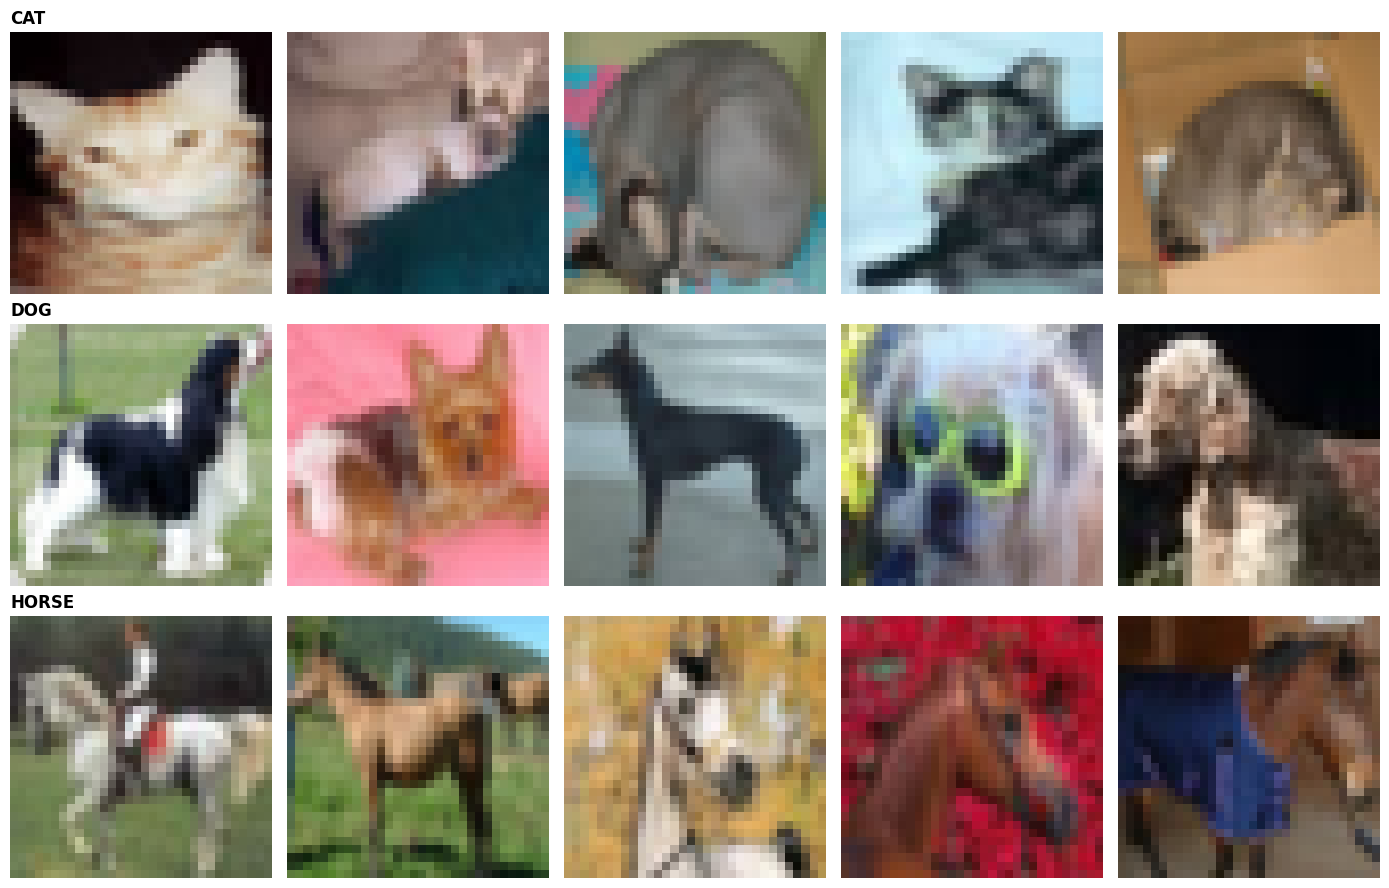

In [ ]:
# Look at some training images
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
for r, cls in enumerate(classes):
    paths = random.sample([p for p, c in files["train"] if c == cls], 5)
    for c_idx, p in enumerate(paths):
        axes[r, c_idx].imshow(Image.open(p).convert("RGB"))
        axes[r, c_idx].axis("off")
        if c_idx == 0:
            axes[r, c_idx].set_title(cls.upper(), loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 3️⃣ Load the data

> ⚠️ **The key bug fix:** `class_names` is read **immediately after loading**, before `.prefetch()` wraps the dataset (which removes that attribute). It is then saved to disk so the web app uses the exact same label order.

The test set is **not shuffled** so predictions line up with their true labels in the evaluation step.

In [ ]:
common = dict(image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int")

train_raw = keras.utils.image_dataset_from_directory(f"{DATA_ROOT}/train",      shuffle=True,  seed=SEED, **common)
val_raw   = keras.utils.image_dataset_from_directory(f"{DATA_ROOT}/validation", shuffle=False, **common)
test_raw  = keras.utils.image_dataset_from_directory(f"{DATA_ROOT}/test",       shuffle=False, **common)

# ✅ Read class names NOW (before the pipeline wrapping below drops the attribute)
CLASS_NAMES = train_raw.class_names
NUM_CLASSES = len(CLASS_NAMES)
assert CLASS_NAMES == val_raw.class_names == test_raw.class_names, "Class folders differ between splits!"

with open("class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)

print("\nClass mapping:")
for i, n in enumerate(CLASS_NAMES):
    print(f"  index {i} -> {n}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.prefetch(AUTOTUNE)
val_ds   = val_raw.cache().prefetch(AUTOTUNE)
test_ds  = test_raw.cache().prefetch(AUTOTUNE)

Found 2100 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 450 files belonging to 3 classes.

Class mapping:
  index 0 -> cat
  index 1 -> dog
  index 2 -> horse


## 4️⃣ Build the model

**Transfer learning with MobileNetV2** (pre-trained on ImageNet):

```
Input (224×224×3, raw pixels 0-255)
 → Data augmentation   (flip, rotation, zoom, shift, contrast; active only while training)
 → Rescaling to [-1, 1] (what MobileNetV2 expects)
 → MobileNetV2 backbone (pre-trained, frozen at first)
 → Global average pooling
 → Dropout 0.3
 → Dense(3, softmax)
```

Because augmentation and rescaling are **layers inside the model**, any raw image can be passed in at prediction time — no separate preprocessing to forget.

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.15),
], name="augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
)
base_model.trainable = False  # stage 1: backbone frozen

inputs  = keras.Input(shape=IMG_SIZE + (3,), name="image")
x = data_augmentation(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1, name="rescale")(x)   # [0,255] -> [-1,1]
x = base_model(x, training=False)                               # keep BatchNorm in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

model = keras.Model(inputs, outputs, name="cat_dog_horse_classifier")
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cat_dog_horse_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5️⃣ Training — Stage 1: train the new classifier head

The backbone is frozen, so only the final `Dense` layer learns. This is fast and gives a strong starting point.

In [ ]:
def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7),
    ]

history_head = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_HEAD, callbacks=make_callbacks(),
)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 102ms/step - accuracy: 0.5614 - loss: 1.0105 - val_accuracy: 0.7400 - val_loss: 0.6389 - learning_rate: 0.0010
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.7095 - loss: 0.6901 - val_accuracy: 0.7667 - val_loss: 0.6131 - learning_rate: 0.0010
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.7552 - loss: 0.6119 - val_accuracy: 0.8000 - val_loss: 0.5067 - learning_rate: 0.0010
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.7633 - loss: 0.5782 - val_accuracy: 0.8267 - val_loss: 0.5041 - learning_rate: 0.0010
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.7781 - loss: 0.5425 - val_accuracy: 0.8156 - val_loss: 0.5100 - learning_rate: 0.0010
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.7776 - loss: 0.5434 - val_accuracy: 0.8133 - val_loss: 0.4892 - learning_rate: 0.0010
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.8029 - loss: 0.5107 - val_a

## 6️⃣ Training — Stage 2: fine-tuning

We unfreeze the **top layers** of MobileNetV2 and train them with a **very small learning rate** so the pre-trained features are gently adapted to cats, dogs and horses. BatchNorm layers stay frozen for stability.

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Must re-compile after changing `trainable`
model.compile(
    optimizer=keras.optimizers.Adam(2e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_fine = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_FINE, callbacks=make_callbacks(),
)

Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 14s 117ms/step - accuracy: 0.7824 - loss: 0.5275 - val_accuracy: 0.8311 - val_loss: 0.4283 - learning_rate: 2.0000e-05
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - accuracy: 0.8200 - loss: 0.4358 - val_accuracy: 0.8533 - val_loss: 0.3860 - learning_rate: 2.0000e-05
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.8514 - loss: 0.3852 - val_accuracy: 0.8444 - val_loss: 0.3703 - learning_rate: 2.0000e-05
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 106ms/step - accuracy: 0.8467 - loss: 0.3749 - val_accuracy: 0.8644 - val_loss: 0.3728 - learning_rate: 2.0000e-05
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 116ms/step - accuracy: 0.8576 - loss: 0.3580 - val_accuracy: 0.8600 - val_loss: 0.3865 - learning_rate: 2.0000e-05
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.8714 - loss: 0.3313 - val_accuracy: 0.8644 - val_loss: 0.3578 - learning_rate: 1.0000e-05
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 6s 85ms/step - accuracy: 0.8

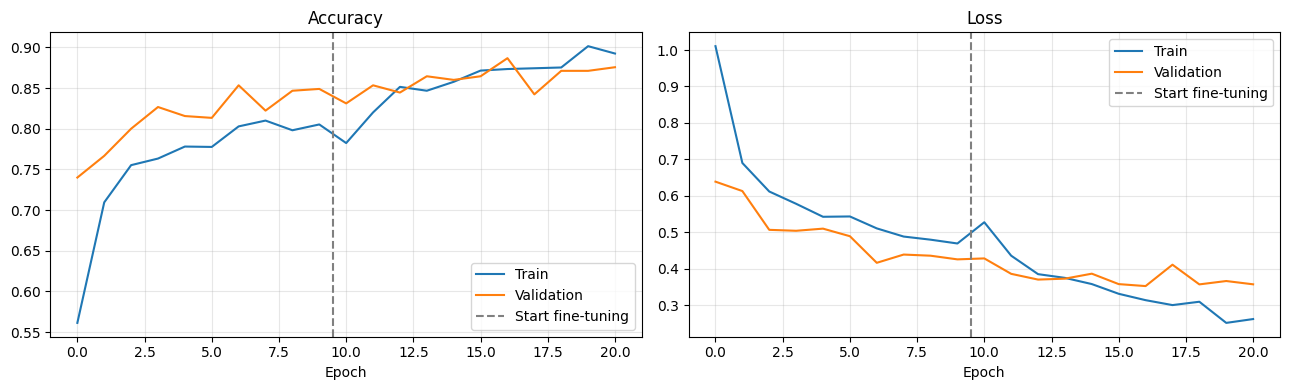

In [ ]:
# Training curves (both stages combined; the dashed line marks where fine-tuning starts)
def merge(key):
    return history_head.history[key] + history_fine.history[key]

split_at = len(history_head.history["accuracy"]) - 0.5
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (k, title) in zip(ax, [("accuracy", "Accuracy"), ("loss", "Loss")]):
    a.plot(merge(k), label="Train")
    a.plot(merge("val_" + k), label="Validation")
    a.axvline(split_at, color="gray", linestyle="--", label="Start fine-tuning")
    a.set_title(title); a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7️⃣ Evaluate on the unseen test set

The test images were never used for training or for choosing when to stop, so this is an honest estimate of real-world performance.

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc * 100:.2f}%")

Test loss    : 0.3280
Test accuracy: 87.78%


In [ ]:
# Collect predictions (test set is not shuffled, so order is stable)
y_true, y_prob, test_images = [], [], []
for xb, yb in test_ds:
    y_prob.append(model.predict(xb, verbose=0))
    y_true.append(yb.numpy())
    test_images.append(xb.numpy().astype("uint8"))

y_prob = np.concatenate(y_prob)
y_true = np.concatenate(y_true)
test_images = np.concatenate(test_images)
y_pred = y_prob.argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

         cat     0.7989    0.9267    0.8580       150
         dog     0.9200    0.7667    0.8364       150
       horse     0.9338    0.9400    0.9369       150

    accuracy                         0.8778       450
   macro avg     0.8842    0.8778    0.8771       450
weighted avg     0.8842    0.8778    0.8771       450



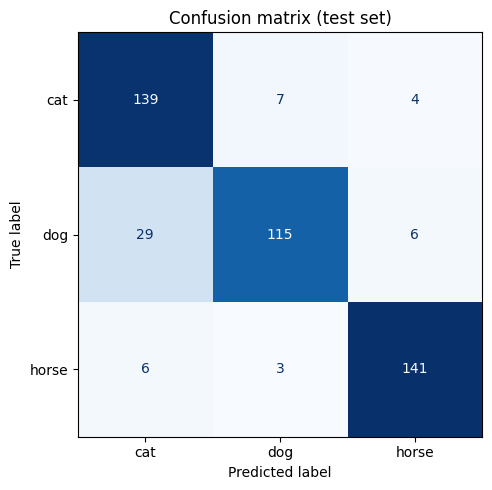

In [ ]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)   # shown later in the Streamlit app
plt.show()

Misclassified: 55 of 450


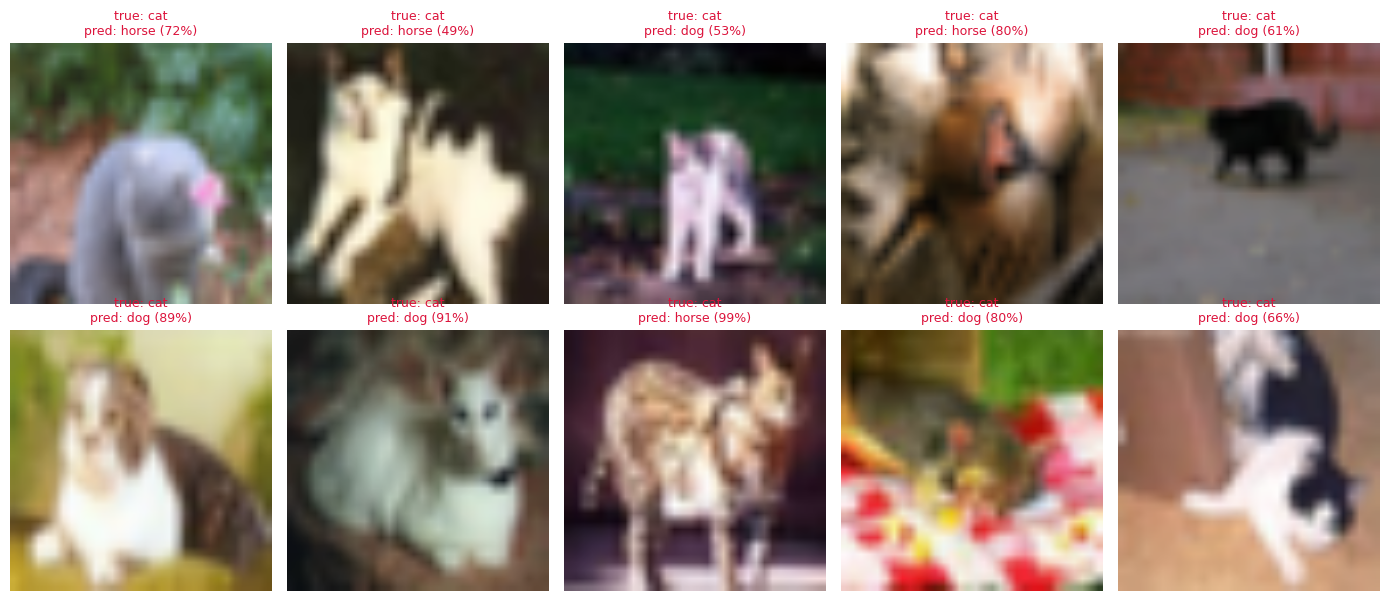

In [ ]:
# Which images did the model get wrong?
wrong = np.where(y_pred != y_true)[0]
print(f"Misclassified: {len(wrong)} of {len(y_true)}")

if len(wrong):
    show = wrong[:10]
    cols = 5
    rows = int(np.ceil(len(show) / cols))
    plt.figure(figsize=(14, 3 * rows))
    for i, idx in enumerate(show):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(test_images[idx]); plt.axis("off")
        plt.title(f"true: {CLASS_NAMES[y_true[idx]]}\npred: {CLASS_NAMES[y_pred[idx]]} ({y_prob[idx].max()*100:.0f}%)",
                  fontsize=9, color="crimson")
    plt.tight_layout(); plt.show()

## 8️⃣ Save the model & predict on a single image

We save three files that the Streamlit app needs: the model, the class names and the metrics.

In [ ]:
model.save(MODEL_PATH)

per_class = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
metrics = {
    "test_accuracy": float(test_acc),
    "test_loss": float(test_loss),
    "test_samples": int(len(y_true)),
    "class_names": CLASS_NAMES,
    "per_class": {c: {k: float(v) for k, v in per_class[c].items()} for c in CLASS_NAMES},
}
with open("metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:", MODEL_PATH, "| class_names.json | metrics.json | confusion_matrix.png")

Saved: cat_dog_horse_model.keras | class_names.json | metrics.json | confusion_matrix.png



True class: cat
Prediction: CAT  (97.9%)
  Cat      97.94%
  Dog       1.26%
  Horse     0.79%


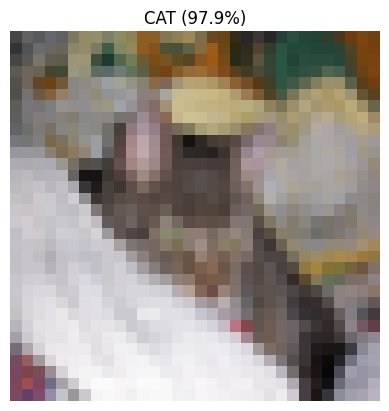


True class: dog
Prediction: DOG  (95.8%)
  Dog      95.79%
  Cat       4.11%
  Horse     0.10%


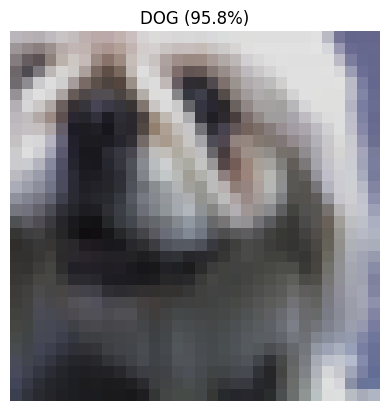


True class: horse
Prediction: HORSE  (100.0%)
  Horse    99.96%
  Cat       0.03%
  Dog       0.01%


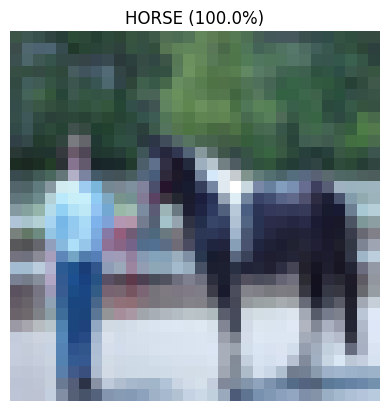

In [ ]:
# Reload from disk + class names from JSON, exactly like the web app does
loaded_model = keras.models.load_model(MODEL_PATH)
with open("class_names.json") as f:
    LOADED_CLASSES = json.load(f)

def predict_image(path, mdl=loaded_model, class_names=LOADED_CLASSES, show=True):
    """Predict a single image file. Same preprocessing as the Streamlit app."""
    img = Image.open(path).convert("RGB")
    arr = tf.image.resize(np.asarray(img, dtype="float32"), IMG_SIZE).numpy()   # bilinear, like training
    probs = mdl.predict(arr[None, ...], verbose=0)[0]
    top = int(np.argmax(probs))
    if show:
        print(f"Prediction: {class_names[top].upper()}  ({probs[top]*100:.1f}%)")
        for n, p in sorted(zip(class_names, probs), key=lambda t: -t[1]):
            print(f"  {n.capitalize():<8}{p*100:6.2f}%")
        plt.imshow(img); plt.axis("off")
        plt.title(f"{class_names[top].upper()} ({probs[top]*100:.1f}%)"); plt.show()
    return class_names[top], probs

# --- Option A: one random image per class from the test set -----------------
for cls in LOADED_CLASSES:
    path = random.choice([p for p, c in files["test"] if c == cls])
    print(f"\nTrue class: {cls}")
    predict_image(path)

# --- Option B: your own image (uncomment & set the path) --------------------
# predict_image("/content/dog1.jpeg")

In [ ]:
# Sanity check: the model reloaded from disk must give the same answers as the one in memory
reload_pred = loaded_model.predict(test_ds, verbose=0).argmax(axis=1)
print("Reloaded model matches in-memory model:", bool(np.array_equal(reload_pred, y_pred)))

Reloaded model matches in-memory model: True


## 9️⃣ Streamlit frontend

The cell below writes `app.py`. The app offers:

- 📁 image upload **or** 📷 camera capture
- a big result card with the predicted class and confidence
- a probability bar for every class
- a warning when the model is unsure (confidence < 60 %)
- a sidebar with the test accuracy and the confusion matrix (great for presenting)

In [ ]:
%%writefile app.py
"""
Cat / Dog / Horse Classifier - Streamlit frontend
Run with:  streamlit run app.py
Needs in the same folder: cat_dog_horse_model.keras, class_names.json
(optional: metrics.json, confusion_matrix.png)
"""
import json
import os

import numpy as np
import streamlit as st
import tensorflow as tf
from PIL import Image, ImageOps

# ----------------------------------------------------------------- config
MODEL_PATH = "cat_dog_horse_model.keras"
CLASSES_PATH = "class_names.json"
METRICS_PATH = "metrics.json"
CONFMAT_PATH = "confusion_matrix.png"
EMOJI = {"cat": "🐱", "dog": "🐶", "horse": "🐴"}
CONFIDENCE_THRESHOLD = 0.60  # below this we warn the user

st.set_page_config(page_title="Cat • Dog • Horse Classifier", page_icon="🐾", layout="centered")

st.markdown(
    """
    <style>
    .result-card {padding: 1.4rem; border-radius: 16px; text-align: center;
                  background: linear-gradient(135deg, #4f46e5 0%, #7c3aed 100%); color: white;}
    .result-card h1 {margin: 0; font-size: 3rem; color: white;}
    .result-card p  {margin: .2rem 0 0 0; font-size: 1.2rem; opacity: .9;}
    </style>
    """,
    unsafe_allow_html=True,
)


# ----------------------------------------------------------------- loading
@st.cache_resource(show_spinner="Loading model...")
def load_assets():
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(CLASSES_PATH) as f:
        class_names = json.load(f)
    metrics = None
    if os.path.exists(METRICS_PATH):
        with open(METRICS_PATH) as f:
            metrics = json.load(f)
    return model, class_names, metrics


def preprocess(img: Image.Image, size) -> np.ndarray:
    """Same preprocessing as in the notebook (resize only - scaling is inside the model)."""
    img = ImageOps.exif_transpose(img).convert("RGB")  # fixes rotated phone photos, drops alpha
    arr = np.asarray(img, dtype="float32")
    arr = tf.image.resize(arr, size).numpy()  # bilinear, identical to training pipeline
    return np.expand_dims(arr, axis=0)


def predict(model, img, size):
    return model.predict(preprocess(img, size), verbose=0)[0]


# ----------------------------------------------------------------- sanity check
missing = [p for p in (MODEL_PATH, CLASSES_PATH) if not os.path.exists(p)]
if missing:
    st.error(f"Missing file(s): {', '.join(missing)}. Run the notebook first and put them next to app.py.")
    st.stop()

model, class_names, metrics = load_assets()
IMG_SIZE = tuple(model.input_shape[1:3])

# ----------------------------------------------------------------- sidebar
with st.sidebar:
    st.header("ℹ️ About")
    st.write(
        "A CNN built with **transfer learning (MobileNetV2)** that tells apart "
        "**cats, dogs and horses**."
    )
    if metrics:
        st.metric("Test accuracy", f"{metrics['test_accuracy'] * 100:.2f}%")
        st.caption(f"Evaluated on {metrics.get('test_samples', '?')} unseen images.")
    st.write("**Classes:** " + ", ".join(f"{EMOJI.get(c, '')} {c}" for c in class_names))
    st.write(f"**Input size:** {IMG_SIZE[0]}×{IMG_SIZE[1]}")
    if os.path.exists(CONFMAT_PATH):
        with st.expander("Confusion matrix (test set)"):
            st.image(CONFMAT_PATH, width="stretch")

# ----------------------------------------------------------------- main page
st.title("🐾 Cat • Dog • Horse Classifier")
st.write("Upload a photo (or take one) and the model will tell you what it sees.")

tab_upload, tab_camera = st.tabs(["📁 Upload image", "📷 Use camera"])
with tab_upload:
    uploaded = st.file_uploader("Choose an image", type=["jpg", "jpeg", "png", "webp"])
with tab_camera:
    camera = st.camera_input("Take a picture")

source = uploaded or camera

if source is None:
    st.info("👆 Provide an image to get a prediction.")
else:
    image = Image.open(source)
    probs = predict(model, image, IMG_SIZE)
    top = int(np.argmax(probs))
    label, conf = class_names[top], float(probs[top])

    col_img, col_res = st.columns([1, 1], gap="large")
    with col_img:
        st.image(image, caption="Your image", width="stretch")
    with col_res:
        st.markdown(
            f"""<div class="result-card">
                    <h1>{EMOJI.get(label, '')} {label.capitalize()}</h1>
                    <p>{conf * 100:.1f}% confident</p>
                </div>""",
            unsafe_allow_html=True,
        )
        if conf < CONFIDENCE_THRESHOLD:
            st.warning("The model is not very sure. The image may not be a cat, dog or horse.")

    st.subheader("Probability breakdown")
    for idx in np.argsort(probs)[::-1]:
        name = class_names[int(idx)]
        st.write(f"{EMOJI.get(name, '')} **{name.capitalize()}** — {probs[idx] * 100:.1f}%")
        st.progress(float(probs[idx]))

Writing app.py


In [ ]:
%%writefile requirements.txt
tensorflow
streamlit>=1.50
pillow
numpy

Writing requirements.txt


In [ ]:
model.save("cat_dog_horse_model.keras")